# Day 1, step 1: explore and clean the data

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_PATH = "../data/mumbai_area_weather_1980_2025.csv"
CLEAN_PATH = "../data/mumbai_clean.csv"
AREA = "South_Mumbai"
RAW_COLS = ["temperature_2m", "shortwave_radiation", "precipitation"]

## 2. Load the raw data

In [2]:
raw = pd.read_csv(RAW_PATH, usecols=["time", "area"] + RAW_COLS)
raw["time"] = pd.to_datetime(raw["time"])

print(f"{len(raw):,} rows")
print("Areas:", raw["area"].unique().tolist())
raw.head()

1,209,744 rows
Areas: ['Central_Mumbai', 'South_Mumbai', 'Western_Mumbai']


,time,area,temperature_2m,precipitation,shortwave_radiation
0,1980-01-01 00:00:00,Central_Mumbai,22.2,0.0,0.0
1,1980-01-01 00:00:00,South_Mumbai,22.3,0.0,0.0
2,1980-01-01 00:00:00,Western_Mumbai,22.3,0.0,0.0
3,1980-01-01 01:00:00,Central_Mumbai,21.9,0.0,0.0
4,1980-01-01 01:00:00,South_Mumbai,22.0,0.0,0.0


## 3. Check: one area or copies?

In [3]:
areas = raw["area"].unique()
if len(areas) > 1:
    wide = raw.pivot(index="time", columns="area", values="temperature_2m")
    for other in areas:
        if other != AREA:
            same = (wide[AREA] == wide[other]).mean()
            diff = (wide[AREA] - wide[other]).abs().mean()
            print(f"{AREA} vs {other}: identical in {same:.0%} of hours, average difference {diff:.2f} C")
else:
    print("Only one area in the file:", areas[0])

South_Mumbai vs Central_Mumbai: identical in 50% of hours, average difference 0.05 C
South_Mumbai vs Western_Mumbai: identical in 100% of hours, average difference 0.00 C


In [4]:
df = raw[raw["area"] == AREA].drop(columns="area").set_index("time").sort_index()
print(f"{len(df):,} hours for {AREA}")

403,248 hours for South_Mumbai


## 4. Check: duplicate hours and missing hours

In [5]:
duplicates = df.index.duplicated().sum()
expected = pd.date_range(df.index.min(), df.index.max(), freq="h")
missing_hours = expected.difference(df.index)

print(f"Duplicate hours: {duplicates}")
print(f"Missing hours:   {len(missing_hours)}  (expected {len(expected):,}, have {len(df):,})")

Duplicate hours: 0
Missing hours:   0  (expected 403,248, have 403,248)


## 5. Check: missing values

In [6]:
print(df.isna().sum())

temperature_2m         0
precipitation          0
shortwave_radiation    0
dtype: int64


## 6. Check: impossible values

In [7]:
night = df.index.hour.isin([21, 22, 23, 0, 1, 2, 3, 4])

problems = {
    "temperature outside 5-45 C": (~df["temperature_2m"].between(5, 45)).sum(),
    "sunlight outside 0-1400": (~df["shortwave_radiation"].between(0, 1400)).sum(),
    "negative rain": (df["precipitation"] < 0).sum(),
    "sunlight at night": (df.loc[night, "shortwave_radiation"] > 0).sum(),
}
pd.Series(problems, name="rows with a problem")

temperature outside 5-45 C    0
sunlight outside 0-1400       0
negative rain                 0
sunlight at night             0
Name: rows with a problem, dtype: int64

## 7. Check: sudden jumps (real or errors?)

Hours with a jump of 3 C or more: 7,987 of 403,248 (2.0%)
  rises: 6,595  |  drops: 1,392
  drops with rain: 2%


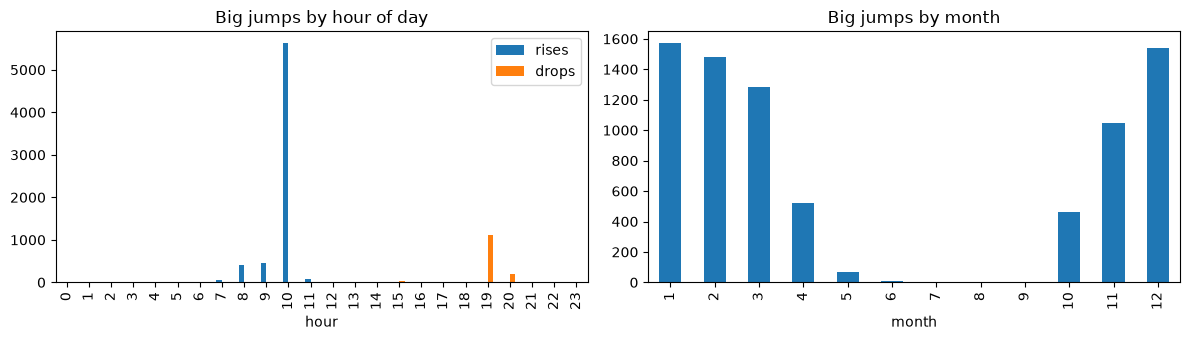

In [8]:
jump = df["temperature_2m"].diff()
rises = jump[jump >= 3]
drops = jump[jump <= -3]

print(f"Hours with a jump of 3 C or more: {len(rises) + len(drops):,} of {len(df):,} "
      f"({(len(rises) + len(drops)) / len(df):.1%})")
print(f"  rises: {len(rises):,}  |  drops: {len(drops):,}")
rain_now_or_before = (df["precipitation"] > 0) | (df["precipitation"].shift(1) > 0)
print(f"  drops with rain: {rain_now_or_before[drops.index].mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pd.DataFrame({
    "rises": rises.groupby(rises.index.hour).size(),
    "drops": drops.groupby(drops.index.hour).size(),
}).reindex(range(24), fill_value=0).plot.bar(ax=axes[0], title="Big jumps by hour of day")
axes[0].set_xlabel("hour")
big_all = jump[jump.abs() >= 3]
big_all.groupby(big_all.index.month).size().reindex(range(1, 13), fill_value=0).plot.bar(
    ax=axes[1], title="Big jumps by month")
axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()

## 8. Clean and save

In [9]:
clean = df[~df.index.duplicated(keep="first")]
clean = clean.reindex(pd.date_range(clean.index.min(), clean.index.max(), freq="h"))
clean.index.name = "time"
clean = clean.interpolate(limit=3)

clean["shortwave_radiation"] = clean["shortwave_radiation"].clip(lower=0)
clean["precipitation"] = clean["precipitation"].clip(lower=0)
clean.loc[clean.index.hour.isin([21, 22, 23, 0, 1, 2, 3, 4]), "shortwave_radiation"] = 0

changed = (clean.reindex(df.index) != df).sum().sum() + (len(clean) - len(df))
print(f"Values changed or added by cleaning: {changed}")
print(f"Missing values left: {clean.isna().sum().sum()}")

clean.to_csv(CLEAN_PATH)
print(f"Saved {len(clean):,} clean hours to {CLEAN_PATH}")

Values changed or added by cleaning: 0
Missing values left: 0


Saved 403,248 clean hours to ../data/mumbai_clean.csv


## 9. Explore temperature

count    403248.00
mean         26.73
std           3.17
min          13.10
25%          25.20
50%          26.90
75%          28.70
max          37.60
Name: temperature_2m, dtype: float64


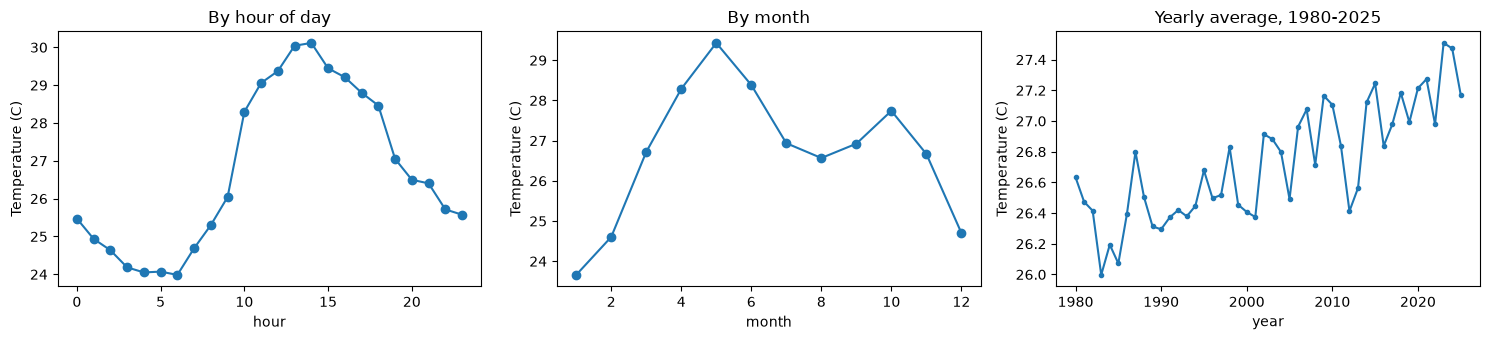

Warming: 26.38 C (1980s) -> 27.16 C (last 10 years)


In [10]:
temp = clean["temperature_2m"]
print(temp.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
temp.groupby(temp.index.hour).mean().plot(ax=axes[0], marker="o", title="By hour of day")
temp.groupby(temp.index.month).mean().plot(ax=axes[1], marker="o", title="By month")
temp.groupby(temp.index.year).mean().plot(ax=axes[2], marker=".", title="Yearly average, 1980-2025")
axes[0].set_xlabel("hour")
axes[1].set_xlabel("month")
axes[2].set_xlabel("year")
for ax in axes:
    ax.set_ylabel("Temperature (C)")
plt.tight_layout()
plt.show()

yearly = temp.groupby(temp.index.year).mean()
print(f"Warming: {yearly.loc[1980:1989].mean():.2f} C (1980s) -> {yearly.loc[2016:2025].mean():.2f} C (last 10 years)")

## 10. Explore sunlight (`shortwave_radiation`)

Hours with sunlight > 0: 54%


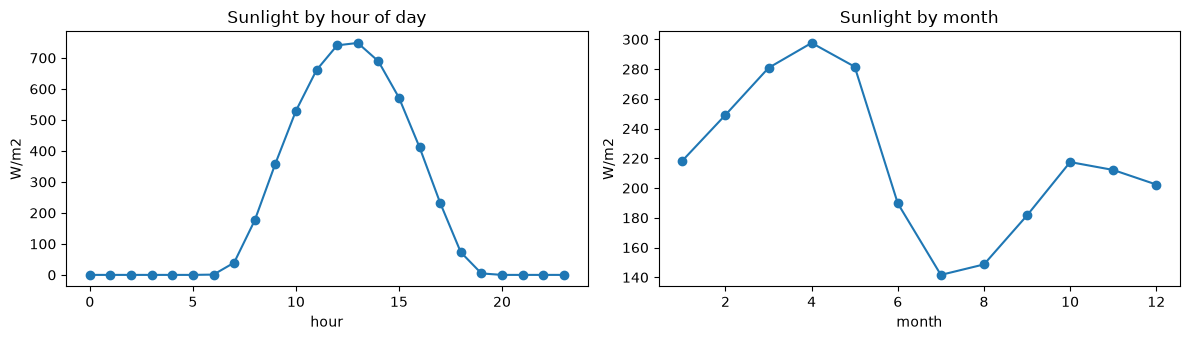

In [11]:
sun = clean["shortwave_radiation"]
print(f"Hours with sunlight > 0: {(sun > 0).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sun.groupby(sun.index.hour).mean().plot(ax=axes[0], marker="o", title="Sunlight by hour of day")
sun.groupby(sun.index.month).mean().plot(ax=axes[1], marker="o", title="Sunlight by month")
axes[0].set_xlabel("hour")
axes[1].set_xlabel("month")
for ax in axes:
    ax.set_ylabel("W/m2")
plt.tight_layout()
plt.show()

## 11. Explore rain (`precipitation`)

Hours with rain: 28%  |  hours with no rain: 72%


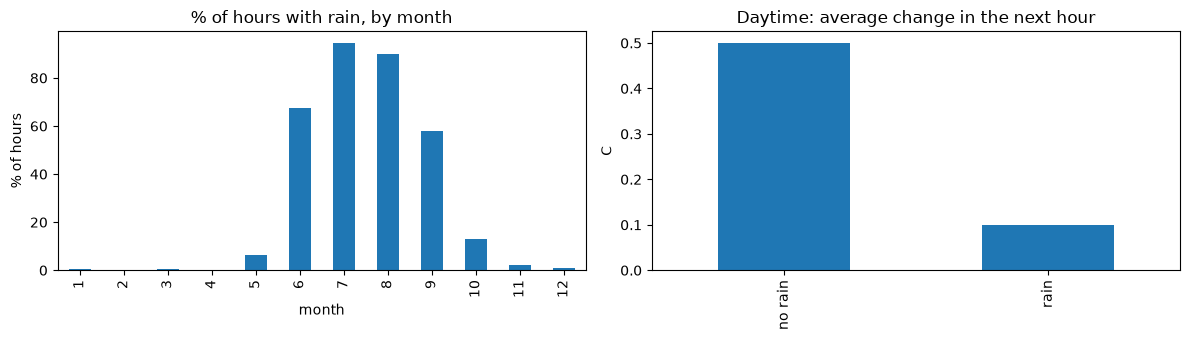

Share of all rain that falls in Jun-Sep: 95%
Daytime change per hour: no rain +0.50 C, rain +0.10 C


In [12]:
rain = clean["precipitation"]
rainy = rain > 0
print(f"Hours with rain: {rainy.mean():.0%}  |  hours with no rain: {(~rainy).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
rainy.groupby(rain.index.month).mean().mul(100).plot.bar(ax=axes[0], title="% of hours with rain, by month")
axes[0].set_ylabel("% of hours")
axes[0].set_xlabel("month")

change_next = temp.shift(-1) - temp
daytime = clean.index.hour.isin(range(8, 17))
daytime_change = pd.Series({
    "no rain": change_next[daytime & ~rainy].mean(),
    "rain": change_next[daytime & rainy].mean(),
})
daytime_change.plot.bar(ax=axes[1], title="Daytime: average change in the next hour")
axes[1].set_ylabel("C")
plt.tight_layout()
plt.show()

monsoon_share = rain[rain.index.month.isin([6, 7, 8, 9])].sum() / rain.sum()
print(f"Share of all rain that falls in Jun-Sep: {monsoon_share:.0%}")
print(f"Daytime change per hour: no rain {daytime_change['no rain']:+.2f} C, rain {daytime_change['rain']:+.2f} C")

## 12. Build the 6 features and see how they relate to the target

In [13]:
features = pd.DataFrame(index=clean.index)
features["temp_now"] = temp
features["temp_3h_ago"] = temp.shift(3)
features["temp_avg_24h"] = temp.rolling(24).mean()
features["sunlight"] = sun
features["rain"] = rain
features["hour"] = clean.index.hour
features["temp_next_hour"] = temp.shift(-1)
features = features.dropna()

print(features.describe().round(2))
features.corr()["temp_next_hour"].drop("temp_next_hour").sort_values(ascending=False).round(3)

        temp_now  temp_3h_ago  temp_avg_24h   sunlight       rain       hour  \
count  403224.00    403224.00     403224.00  403224.00  403224.00  403224.00   
mean       26.73        26.73         26.73     218.20       0.22      11.50   
std         3.17         3.17          1.99     298.19       0.74       6.92   
min        13.10        13.10         17.62       0.00       0.00       0.00   
25%        25.20        25.20         25.65       0.00       0.00       5.75   
50%        26.90        26.90         26.87       9.00       0.00      11.50   
75%        28.70        28.70         28.05     423.00       0.10      17.25   
max        37.60        37.60         32.67    1039.00      32.00      23.00   

       temp_next_hour  
count       403224.00  
mean            26.73  
std              3.17  
min             13.10  
25%             25.20  
50%             26.90  
75%             28.70  
max             37.60  


temp_now        0.957
sunlight        0.655
temp_3h_ago     0.633
temp_avg_24h    0.619
hour            0.268
rain           -0.006
Name: temp_next_hour, dtype: float64

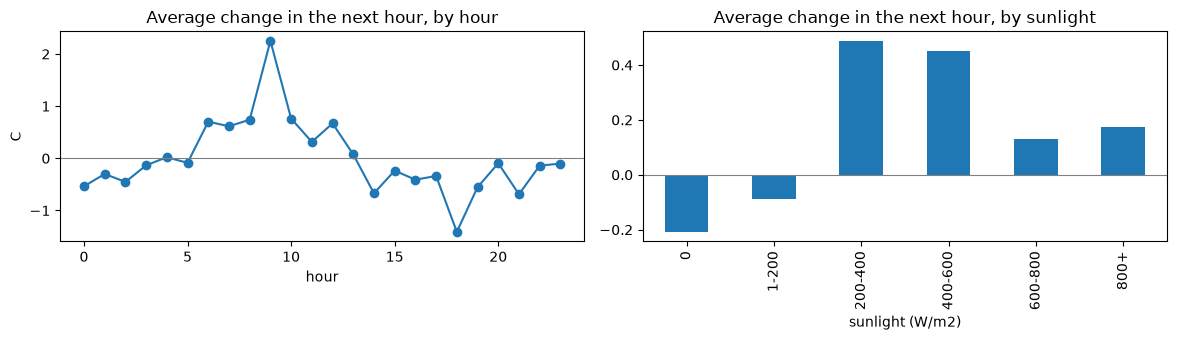

In [14]:
change = features["temp_next_hour"] - features["temp_now"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
change.groupby(features["hour"]).mean().plot(ax=axes[0], marker="o", title="Average change in the next hour, by hour")
axes[0].axhline(0, color="grey", linewidth=0.8)
axes[0].set_xlabel("hour")
axes[0].set_ylabel("C")

sun_bins = pd.cut(features["sunlight"], [-1, 0, 200, 400, 600, 800, 1400],
                  labels=["0", "1-200", "200-400", "400-600", "600-800", "800+"])
change.groupby(sun_bins, observed=True).mean().plot.bar(ax=axes[1], title="Average change in the next hour, by sunlight")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("sunlight (W/m2)")
plt.tight_layout()
plt.show()